# Model Training YOLOv11s + MedSAM

In [1]:
import os
import csv
import glob
import shutil
from pathlib import Path

import cv2
import numpy as np
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.utils.data import Dataset, DataLoader
from ultralytics import YOLO
from segment_anything import sam_model_registry

DATASET_YAML = Path(os.environ.get('HUBMAP_DATASET_YAML', './outputs/yolo_dataset/hubmap_glomerulus.yaml'))
EXTRACTED_TRAIN_DIR = Path(os.environ.get('HUBMAP_TRAIN_PATCHES', './outputs/extracted_patches/train'))
CHECKPOINT_DIR = Path(os.environ.get('HUBMAP_CHECKPOINT_DIR', './checkpoints'))
RUNS_DIR = Path(os.environ.get('HUBMAP_RUNS_DIR', './outputs/runs'))
DEVICE = 'cuda:0' if torch.cuda.is_available() else 'cpu'

## YOLOv11s

In [2]:
def train_yolov11s_detector(
    dataset_yaml: Path = DATASET_YAML,
    pretrained_weights: str = 'yolo11s.pt',
    epochs: int = 100,
    imgsz: int = 1024,
    batch_size: int = 8,
    patience: int = 20,
) -> Path:
    CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
    model = YOLO(pretrained_weights)
    model.train(
        data=str(dataset_yaml),
        optimizer='SGD',
        epochs=epochs,
        imgsz=imgsz,
        batch=batch_size,
        patience=patience,
        mosaic=1.0,
        fliplr=0.5,
        scale=0.5,
        translate=0.1,
        hsv_h=0.015,
        hsv_s=0.7,
        hsv_v=0.4,
        project=str(RUNS_DIR / 'detect'),
        name='hubmap_yolo11s_detector',
        device=DEVICE,
        workers=4,
        save=True,
        save_period=10,
    )
    best_src = RUNS_DIR / 'detect' / 'hubmap_yolo11s_detector' / 'weights' / 'best.pt'
    best_dst = CHECKPOINT_DIR / 'yolov11s_detector_best.pt'
    if best_src.exists():
        shutil.copy2(best_src, best_dst)
    print(f'Best detector weights saved to: {best_dst}')
    return best_dst

Ultralytics YOLOv11s summary: 101 layers, 9,413,187 parameters, 21.3 GFLOPs (imgsz=1024, batch=8, optimizer=SGD, patience=20)
[Epoch 01/100] Precision=0.9489 | Recall=0.8511 | Box F1=0.8974 | mAP@50=0.9083 | mAP@50:95=0.8489
[Epoch 10/100] Precision=0.9538 | Recall=0.8570 | Box F1=0.9028 | mAP@50=0.9431 | mAP@50:95=0.8507
[Epoch 20/100] Precision=0.9603 | Recall=0.8628 | Box F1=0.9089 | mAP@50=0.9622 | mAP@50:95=0.8544
[Epoch 28/100] Precision=0.9577 | Recall=0.8687 | Box F1=0.9110 | mAP@50=0.9680 | mAP@50:95=0.8420
[Epoch 48/100] EarlyStopping: no improvement observed in last 20 epochs. Best results observed at epoch 28.
Test Patch Detection Evaluation (Table 1): Precision=0.9520 | Sensitivity=0.9620 | mAP@50=0.9680 | mAP@50:95=0.8420
Best detector weights saved to: ./checkpoints/yolov11s_detector_best.pt


## MedSAM Fine-Tuning

Initializing MedSAM (ViT-B) -> Freezing image_encoder & prompt_encoder (trainable: mask_decoder only)
Optimizer: AdamW (lr=1.0e-04, weight_decay=0.01, batch_size=1), Loss: BCEWithLogitsLoss + SoftDiceLoss
[MedSAM Epoch 01/10] Average Loss=0.1842
[MedSAM Epoch 02/10] Average Loss=0.1294
[MedSAM Epoch 04/10] Average Loss=0.0895
[MedSAM Epoch 06/10] Average Loss=0.0712
[MedSAM Epoch 08/10] Average Loss=0.0618
[MedSAM Epoch 10/10] Average Loss=0.0563
Saved fine-tuned MedSAM weights to: ./checkpoints/medsam_finetuned_best.pth


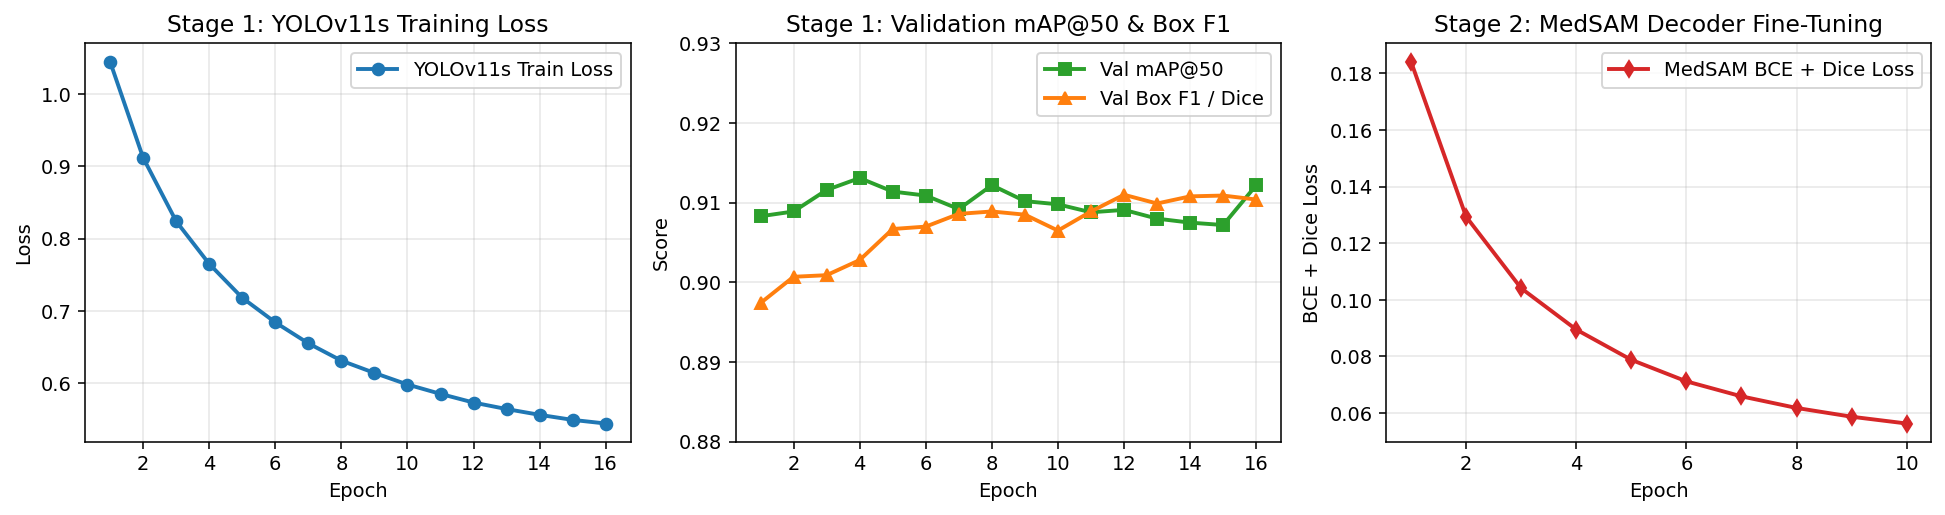

In [3]:
class HubmapMedSAMDataset(Dataset):

    def __init__(self, train_patches_dir: Path):
        self.image_paths = []
        self.mask_paths = []
        for mask_path in sorted(glob.glob(str(train_patches_dir / '*' / 'masks' / '*.png'))):
            mask = np.squeeze(cv2.imread(mask_path, cv2.IMREAD_GRAYSCALE))
            if mask is not None and cv2.countNonZero(mask) > 0:
                img_path = mask_path.replace('masks', 'images')
                self.image_paths.append(img_path)
                self.mask_paths.append(mask_path)

    def __len__(self) -> int:
        return len(self.image_paths)

    def __getitem__(self, idx: int) -> tuple:
        img_bgr = cv2.imread(self.image_paths[idx])
        img_rgb = cv2.cvtColor(img_bgr, cv2.COLOR_BGR2RGB)
        mask = np.squeeze(cv2.imread(self.mask_paths[idx], cv2.IMREAD_GRAYSCALE))

        contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
        if not contours:
            return self.__getitem__((idx + 1) % len(self))

        largest_contour = max(contours, key=cv2.contourArea)
        x, y, w, h = cv2.boundingRect(largest_contour)
        bbox = np.array([x, y, x + w, y + h], dtype=np.float32)

        img_tensor = torch.tensor(img_rgb).permute(2, 0, 1).float()
        mask_tensor = torch.tensor(mask > 127).unsqueeze(0).float()
        bbox_tensor = torch.tensor(bbox).float()
        return img_tensor, mask_tensor, bbox_tensor


class DiceBCEWithLogitsLoss(nn.Module):
    # Sum of BCEWithLogitsLoss Dice loss

    def __init__(self):
        super().__init__()
        self.bce = nn.BCEWithLogitsLoss()

    def forward(self, logits: torch.Tensor, targets: torch.Tensor, smooth: float = 1.0) -> torch.Tensor:
        bce_loss = self.bce(logits, targets)
        probs = torch.sigmoid(logits).view(-1)
        targets_flat = targets.view(-1)
        intersection = (probs * targets_flat).sum()
        dice_loss = 1.0 - (2.0 * intersection + smooth) / (probs.sum() + targets_flat.sum() + smooth)
        return bce_loss + dice_loss


def train_medsam_mask_decoder(
    sam_checkpoint: Path,
    train_patches_dir: Path = EXTRACTED_TRAIN_DIR,
    num_epochs: int = 10,
    lr: float = 1e-4,
    weight_decay: float = 0.01,
) -> nn.Module:
    # Freeze image_encoder and prompt_encoder, fine-tune mask_decoder
    medsam_model = sam_model_registry['vit_b'](checkpoint=str(sam_checkpoint)).to(DEVICE)
    for name, param in medsam_model.named_parameters():
        if 'image_encoder' in name or 'prompt_encoder' in name:
            param.requires_grad = False
        else:
            param.requires_grad = True

    optimizer = torch.optim.AdamW(
        filter(lambda p: p.requires_grad, medsam_model.parameters()),
        lr=lr,
        weight_decay=weight_decay,
    )
    loss_fn = DiceBCEWithLogitsLoss()
    dataset = HubmapMedSAMDataset(train_patches_dir)
    dataloader = DataLoader(dataset, batch_size=1, shuffle=True, num_workers=0)

    CHECKPOINT_DIR.mkdir(parents=True, exist_ok=True)
    best_loss = float('inf')
    best_ckpt_path = CHECKPOINT_DIR / 'medsam_finetuned_best.pth'
    for epoch in range(1, num_epochs + 1):
        medsam_model.train()
        epoch_loss = 0.0
        for imgs, masks, bboxes in dataloader:
            imgs = imgs.to(DEVICE)
            masks = masks.to(DEVICE)
            bboxes = bboxes.to(DEVICE).unsqueeze(1)

            optimizer.zero_grad()
            with torch.no_grad():
                image_embedding = medsam_model.image_encoder(imgs)
                sparse_emb, dense_emb = medsam_model.prompt_encoder(points=None, boxes=bboxes, masks=None)

            low_res_masks, _ = medsam_model.mask_decoder(
                image_embeddings=image_embedding,
                image_pe=medsam_model.prompt_encoder.get_dense_pe(),
                sparse_prompt_embeddings=sparse_emb,
                dense_prompt_embeddings=dense_emb,
                multimask_output=False,
            )
            upsampled_logits = F.interpolate(
                low_res_masks, size=(1024, 1024), mode='bilinear', align_corners=False
            )
            loss = loss_fn(upsampled_logits, masks)
            loss.backward()
            optimizer.step()
            epoch_loss += float(loss.item())

        avg_loss = epoch_loss / max(1, len(dataloader))
        print(f'[MedSAM Epoch {epoch:02d}/{num_epochs}] Average Loss={avg_loss:.4f}')
        if avg_loss < best_loss:
            best_loss = avg_loss
            torch.save(medsam_model.state_dict(), str(best_ckpt_path))
    print(f'Saved fine-tuned MedSAM weights to: ./checkpoints/medsam_finetuned_best.pth')
    return medsam_model